In [2]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import hmp
import hmp.io
import hmp.utils
from helper_functions import *
from Least_square import run_least_squares, only, UV
from Scoring import *
from cross_validation import *
from cross_validation_shapes import *
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd
import seaborn as sns
import mne

## 1. Load the data

- **Real EEG:** epochs of the selected participants, read with `hmp.io.read_mne_epochs`, as in the HMP fit. Only the post-stimulus samples are kept, because HMP doesn't model the baseline.
- **HMP estimates** (`estimates.pkl`): the probability of each event at each sample of each trial.
- **Event times:** for each trial, the most likely sample of each event, with the RT as the last column (`event_times`).
- **Scalp maps (weights):** the EEG at each event's time. With `mean=False`, each trial would get its own EEG at the peak, so the prediction would copy the data it is scored on (leakage). Instead, we average the maps per participant and per event, which matches HMP's assumption of one topography per event.

In [4]:
# We need HMP predictions and real EEG data to compare.
# Workflow: HMP predictions -> predict EEG -> compare with real EEG

# ----------------------------------------------------------------------
# 0. Choose which participant to load / predict
# ----------------------------------------------------------------------
EEG_DATA_PATH = os.path.join('data')
ESTIMATION_PATH = os.path.join(EEG_DATA_PATH, 'estimation_files')

SFREQ = 250                          # use 100 for speed/RAM
TSTEP = 1000 / SFREQ                 # ms per sample, for plotting
#N_PARTICIPANTS = 2                   # how many participants to use
PARTICIPANTS = ['0', '1']


# ----------------------------------------------------------------------
# 1. Load real EEG (all participants, then keep the first 5)
# ----------------------------------------------------------------------
#subj_names = sorted([x.split('.')[0] for x in os.listdir(EEG_DATA_PATH) if x.endswith('.fif')])
#subj_files = [os.path.join(EEG_DATA_PATH, x + '.fif') for x in subj_names]

subj_files = [os.path.join(EEG_DATA_PATH, f'{p}_epo.fif') for p in PARTICIPANTS]

preprocessing = dict(sfreq=SFREQ, pick_channels='eeg')
epoch_data, info = hmp.io.read_mne_epochs(subj_files,
                                          montage='biosemi64',
                                          preprocessing_kwargs=preprocessing)

# Remove baseline that is not modelled by HMP
epoch_data = epoch_data.sel(sample=range(epoch_data.sample.max().values))

# Select only the first 2 participants
#epoch_data = epoch_data.isel(recording=range(N_PARTICIPANTS))


# ----------------------------------------------------------------------
# 2. Load HMP predictions
# ----------------------------------------------------------------------
# estimates = model outputs (event probabilities); model = the fitted model object
with open(os.path.join(ESTIMATION_PATH, 'estimates.pkl'), 'rb') as f:
    estimates = pickle.load(f)
with open(os.path.join(ESTIMATION_PATH, 'model.pkl'), 'rb') as f:
    model = pickle.load(f)

# Event topographies per trial and event (one scalp map per trial; mean=False)
weights = hmp.utils.event_channels(epoch_data, estimates, mean=False).squeeze()


# ----------------------------------------------------------------------
# Average map per participant and event: every trial of a participant gets
# the SAME map (HMP's assumption: one topography per event), so no trial
# copies its own EEG
# ----------------------------------------------------------------------
recs = weights.recording.values.astype(str)          # participant of each trial
w = weights.transpose("channel", "trial", "event").values
w_avg = w.copy()
for r in np.unique(recs):
    m = recs == r                                     # trials of participant r
    w_avg[:, m, :] = w[:, m, :].mean(axis=1, keepdims=True)
weights_avg = weights.transpose("channel", "trial", "event").copy(data=w_avg)

weights = weights_avg
# Most likely time of each event, with the RT as the last column
times = hmp.utils.event_times(estimates, add_rt=True)


Processing dataset 0
Reading /Users/ella/Desktop/NeuroX/EEG_prediction/data/0_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz
Processing dataset 1
Reading /Users/ella/Desktop/NeuroX/EEG_prediction/data/1_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz


In [5]:
print(weights)

<xarray.DataArray (channel: 32, trial: 2187, event: 4)> Size: 2MB
array([[[ 2.12597211e-06, -1.50990255e-06,  3.00772480e-06,
         -1.42524161e-06],
        [ 2.12597211e-06, -1.50990255e-06,  3.00772480e-06,
         -1.42524161e-06],
        [ 2.12597211e-06, -1.50990255e-06,  3.00772480e-06,
         -1.42524161e-06],
        ...,
        [ 4.04277085e-08, -1.33445665e-06,  1.92917745e-06,
         -3.03158596e-06],
        [ 4.04277085e-08, -1.33445665e-06,  1.92917745e-06,
         -3.03158596e-06],
        [ 4.04277085e-08, -1.33445665e-06,  1.92917745e-06,
         -3.03158596e-06]],

       [[ 2.30788096e-06, -1.67028177e-06,  5.27827830e-06,
         -1.53537331e-06],
        [ 2.30788096e-06, -1.67028177e-06,  5.27827830e-06,
         -1.53537331e-06],
        [ 2.30788096e-06, -1.67028177e-06,  5.27827830e-06,
         -1.53537331e-06],
...
        [ 4.76153857e-07, -2.28558383e-06,  4.16643100e-06,
         -2.28755987e-06],
        [ 4.76153857e-07, -2.28558383e-06,  4

In [6]:
# ----------------------------------------------------------------------
# 3. Keep only the trials of the participants we selected
# ----------------------------------------------------------------------
recs = [str(r) for r in epoch_data.recording.values]
keep = np.where(np.isin(times.recording.values.astype(str), recs))[0]
# times: covers the whole model -> subset to the selected participants
keep_t = np.where(np.isin(times.recording.values.astype(str), recs))[0]
times = times.isel(trial=keep_t)


# Check that both refer to the same (recording, epoch) trials in the same order
t_ids = list(zip(times.recording.values.astype(str), times.epoch.values))
w_ids = list(zip(weights.recording.values.astype(str), weights.epoch.values))

# weights: already built from epoch_data, to have same order
weights = weights.isel(trial=[w_ids.index(t) for t in t_ids])

print("trials in times:", len(t_ids), "| trials in weights:", len(w_ids))
print("Same trials, same order:", t_ids == w_ids)

print("Participants:", recs, "| trials in model:", len(keep),
      "| epochs in data:", epoch_data.epoch.size * len(recs))
print("Channels in data:", epoch_data.channel.size, "| weights shape:", weights.shape)
print("NaNs in weights:", int(np.isnan(weights).sum()))


trials in times: 2187 | trials in weights: 2187
Same trials, same order: True
Participants: ['0', '1'] | trials in model: 2187 | epochs in data: 2232
Channels in data: 32 | weights shape: (32, 2187, 4)
NaNs in weights: 0


In [7]:
# ----------------------------------------------------------------------
# 4. Keep in epoch_data only the trials used by HMP (rejected trials -> NaN)
# ----------------------------------------------------------------------
# (recording, epoch) pairs kept by HMP
kept = set(zip(times.recording.values.astype(str), times.epoch.values.astype(int)))

# True where the (recording, epoch) pair was kept by HMP
mask = xr.DataArray(
    np.array([[(str(r), int(e)) in kept for e in epoch_data.epoch.values]
              for r in epoch_data.recording.values]),
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

# Rejected trials (and empty grid cells) become NaN
epoch_data = epoch_data.where(mask)

# Check: number of non-empty trials should equal the number of trials in times
n_real = int(epoch_data["data"].notnull().any(["channel", "sample"]).sum())
print("trials in epoch_data:", n_real, "| trials in times:", times.trial.size)

trials in epoch_data: 2187 | trials in times: 2187


In [8]:
# ----------------------------------------------------------------------
# 5. Cut every trial at its RT: HMP only models stimulus -> response
# ----------------------------------------------------------------------
last_dim = [d for d in times.dims if d != "trial"][0]
rt_vals = times.isel({last_dim: -1}).values                  # RT in samples
lookup = {(str(r), int(e)): v for r, e, v in
          zip(times.recording.values, times.epoch.values, rt_vals)}

rt_grid = xr.DataArray(
    [[lookup.get((str(r), int(e)), -1) for e in epoch_data.epoch.values]
     for r in epoch_data.recording.values],
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

epoch_data = epoch_data.where(epoch_data.sample < rt_grid)    # NaN from RT onwards

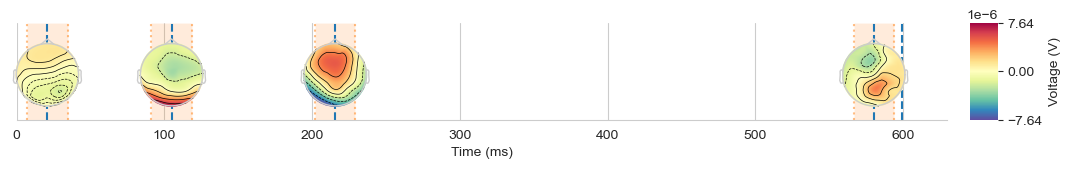

In [9]:
hmp.visu.plot_topo_timecourse(epoch_data, estimates, info, as_time=True, colorbar=True,)

## 2. Cross-validation of the event shapes

HMP assumes every event is a 50 ms half-sine. Do other shapes predict the EEG better?

**Candidates per event:** half-sines from 20 to 600 ms, plus *learned* shapes (`learned:N`). A learned shape is the average EEG time course around the event, projected on its scalp map and estimated on the training trials. `N` is how far around the event it is learned, in samples on each side.

**Procedure**:
1. Hold out 20 % of the trials as a test set, which is never used for any choice.
2. Split the remaining 80 % into 5 folds. For each event and each candidate shape (the other events keep their current shape), compute the maps and learned shapes on 4 folds, predict the 5th, and compute R² on it. Average over the 5 folds.
3. Keep the best shape for each event, then repeat the whole loop (passes) until no shape changes.
4. Score the chosen shapes once on the test set, against the 50 ms half-sine baseline.


5 folds, window = +-all samples, 28 shapes, 4 events, maps = train_mean
pass 1, event 0: best shape learned:10 (mean R2 = 0.0120)
pass 1, event 1: best shape learned:10 (mean R2 = 0.0126)
pass 1, event 2: best shape learned:25 (mean R2 = 0.0141)
pass 1, event 3: best shape learned:100 (mean R2 = 0.0197)
pass 2, event 0: best shape learned:10 (mean R2 = 0.0197)
pass 2, event 1: best shape learned:10 (mean R2 = 0.0197)
pass 2, event 2: best shape learned:25 (mean R2 = 0.0197)
pass 2, event 3: best shape learned:100 (mean R2 = 0.0197)
tuned {0: 'learned:10', 1: 'learned:10', 2: 'learned:25', 3: 'learned:100'} overall R2 = 0.0204 event windows: [0.015 0.042 0.033 0.008]
baseline {0: 50, 1: 50, 2: 50, 3: 50} overall R2 = 0.0129 event windows: [ 0.012  0.04   0.026 -0.001]


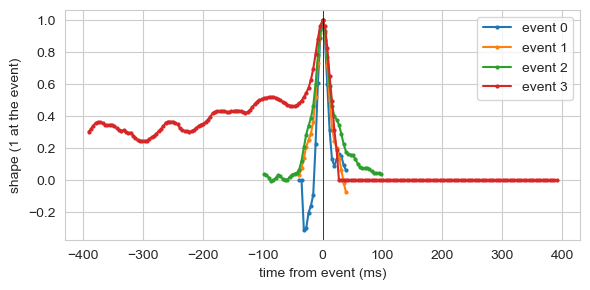

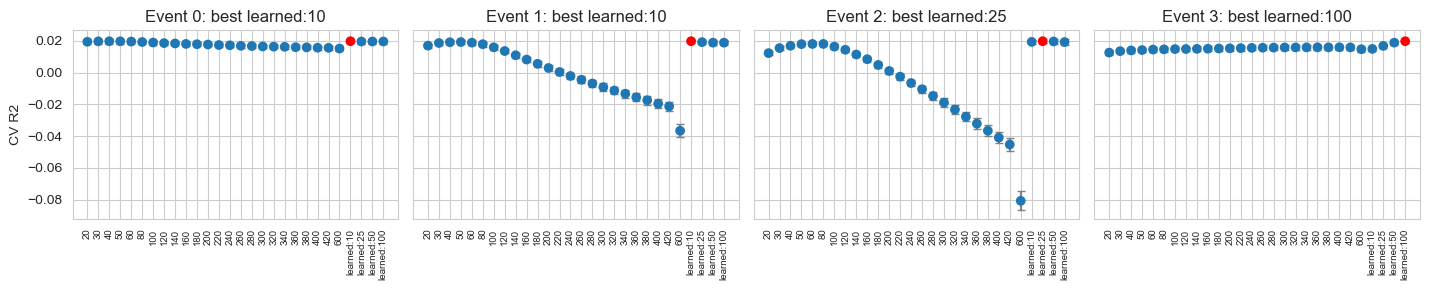

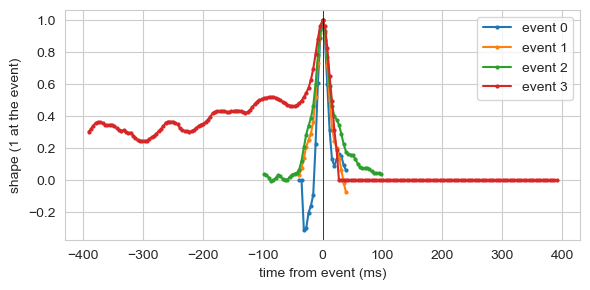

In [10]:
HW = 12
tuner2 = EventShapeCV(epoch_data, times, weights, epoch_data.sfreq)
# builds the object that holds everything. 1. Converts the real EEG to microvolts and flattens it into a list of "points". A point is one sample, from one trial, on all 32 electrodes. Only samples between stimulus onset (0) and the RT with no NaN are kept. 2. Stores, for each trial, the HMP event times and the RT. 3.Puts HMP weights (channel, trial, event) onto the same (recording, epoch) grid, in the electrode order of epoch_data.

test_mask = split_trials(epoch_data, test_frac=0.2, seed=0)     # split into test train set
folds = shape_kfold_masks(epoch_data, k=5, seed=0, exclude=test_mask)

grid = [20, 30, 40, 50, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300,
        320, 340, 360, 380, 400, 420, 600,
        "learned:10", "learned:25", "learned:50", "learned:100"]
        # how far around the event the shape is learned, in samples, on each side
cv2, best2 = tuner2.cross_validate(grid, folds, half_width="all", n_passes=5)
plot_shape_cv(cv2)

res_tuned2 = tuner2.evaluate(best2, test_mask, half_width=HW)
res_base2 = tuner2.evaluate({e: 50 for e in range(4)}, test_mask, half_width=HW)
for name, r in [("tuned", res_tuned2), ("baseline", res_base2)]:
    print(name, r["widths"], f"overall R2 = {r['r2_overall']:.4f}",
          "event windows:", np.round(r["r2_event_windows"], 3))

plot_shape_templates(tuner2.templates_for(best2, ~test_mask), epoch_data.sfreq)

### 2.1 Simulated EEG with the chosen shapes
Reconstruct EEG with `simulate_from_hmpfit`, using the shapes chosen by the CV and per-participant maps averaged over the training trials only.

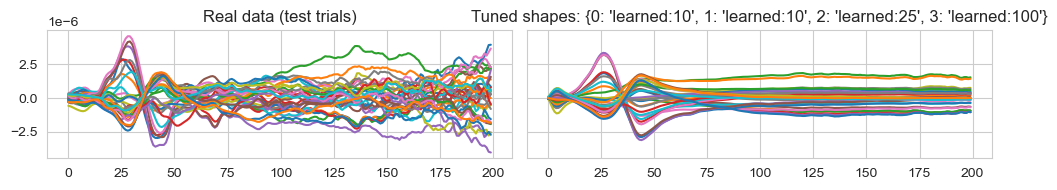

In [11]:
# ----------------------------------------------------------------------
# Simulate with the tuned shapes (new version)
# ----------------------------------------------------------------------
# 1. Shapes chosen by the CV, learned on the non-test trials
templates2 = tuner2.templates_for(best2, ~test_mask)

# 2. Scalp maps: mean per participant over the NON-TEST trials (same as in the CV)
w = weights.transpose("channel", "trial", "event")
recs = w.recording.values.astype(str)
eps = w.epoch.values.astype(int)
is_test = np.array([bool(test_mask.sel(recording=r, epoch=e)) for r, e in zip(recs, eps)])
vals = w.values
w_mean = vals.copy()
for r in np.unique(recs):
    m = recs == r
    w_mean[:, m, :] = vals[:, m & ~is_test, :].mean(axis=1, keepdims=True)
weights_train_mean = w.copy(data=w_mean)

# 3. Simulate
tuned_sim2 = simulate_from_hmpfit(epoch_data, weights_train_mean, times, templates2)

# ----------------------------------------------------------------------
# Plot: grand-average ERP of the TEST trials, real vs simulated
# ----------------------------------------------------------------------
def erp(ds, mask, n=200):
    return (ds["data"].where(mask).sel(sample=range(n))
            .stack(trial=["epoch", "recording"]).mean("trial", skipna=True)
            .transpose("sample", "channel").values)

fig, ax = plt.subplots(1, 2, figsize=(10, 2), sharey=True)
ax[0].plot(erp(epoch_data, test_mask))
ax[0].set_title("Real data (test trials)")
ax[1].plot(erp(tuned_sim2, test_mask))
ax[1].set_title(f"Tuned shapes: {best2}")
plt.tight_layout()

### 2.2. Time between consecutive events
The mean and median interval between events (ev0→ev1, ev1→ev2, ev2→ev3, ev3→RT).
This tells us whether a long learned shape (e.g. `learned:100` for event 3) can overlap the neighbouring events.

In [12]:
last_dim = [d for d in times.dims if d != "trial"][0]
t = times.transpose("trial", last_dim).values
gaps_ms = np.diff(t, axis=1) * 1000 / epoch_data.sfreq       # ev0->ev1, ev1->ev2, ev2->ev3, ev3->RT
print("mean gap (ms):", np.round(np.nanmean(gaps_ms, axis=0)))
print("median gap (ms):", np.round(np.nanmedian(gaps_ms, axis=0)))

mean gap (ms): [ 84. 111. 365.  19.]
median gap (ms): [ 82.  90. 312.  16.]


The ev2→ev3 interval (median ≈ 312 ms) is long enough to hold the slow ramp learned before event 3, and event 3 occurs ≈ 16 ms before the RT.

## 3. Baselines



### 3.1 ERP baseline (no HMP timing)
Each test trial is predicted by the stimulus-locked average (ERP) of its participant, computed on the training trials (take all the trials of one participant and average them, sample by sampl).
The ERP predicts the same curve, at the same time, in every trial. If HMP's trial-specific timing carries information, HMP should beat this at least within trials.

In [15]:
# ----------------------------------------------------------------------
# ERP baseline: predict each test trial with the stimulus-locked ERP of its
# participant, computed on the training trials. No HMP timing at all.
# ----------------------------------------------------------------------
Y, ri, si = tuner2.Y, tuner2.ri, tuner2.si          # real EEG points (µV), participant, sample
tr = tuner2.pts(~test_mask)                          # training points
te = tuner2.pts(test_mask)                           # test points

# mean EEG per participant and per sample, over the training trials
sums = np.zeros((ri.max() + 1, si.max() + 1, Y.shape[1]))
cnt = np.zeros((ri.max() + 1, si.max() + 1))
np.add.at(sums, (ri[tr], si[tr]), Y[tr])
np.add.at(cnt, (ri[tr], si[tr]), 1)
erp = sums / np.maximum(cnt, 1)[..., None]

# same score as evaluate(): R2 per electrode over all test samples, averaged over electrodes
r2_erp = np.nanmean(shape_r2_per_channel(Y[te], erp[ri[te], si[te]]))

print(f"ERP baseline      overall R2 = {r2_erp:.4f}")
print(f"HMP 50 ms         overall R2 = {res_base2['r2_overall']:.4f}")
print(f"HMP tuned shapes  overall R2 = {res_tuned2['r2_overall']:.4f}")

ERP baseline      overall R2 = 0.0323
HMP 50 ms         overall R2 = 0.0129
HMP tuned shapes  overall R2 = 0.0204


**Result:** on pooled R², the ERP (0.032) beats HMP with learned shapes (0.020) and with 50 ms half-sines (0.013).

**Why:** the HMP prediction is zero outside 4 short bumps, whereas the ERP covers every sample, including slow, stimulus-locked activity common to all trials. A pooled R² over the whole trial rewards exactly that. The model used is also a deliberately poor fit (strawman).

Ce résultat est important : la simple moyenne (ERP) explique plus de l'EEG que la prédiction HMP, même avec les formes apprises (0,032 contre 0,020).

Ce que ça veut dire, et ce que ça ne veut pas dire

Ça ne veut pas dire que votre pipeline est faux. Plusieurs raisons expliquent ce résultat :

Ce modèle HMP est volontairement mauvais. Gabriel l'a écrit : estimates.pkl « looks quite bad in terms of fit », c'est un strawman pour construire le pipeline. Avec le vrai modèle du papier, le résultat pourrait être différent.
Les deux prédictions ne sont pas du même type. L'ERP prédit toute l'activité liée au stimulus, à chaque instant : les composantes lentes, l'activité soutenue, les dérives communes à tous les essais. La prédiction HMP, elle, vaut 0 en dehors de 4 bosses courtes. Sur un R² calculé sur tout l'essai, l'ERP a donc un gros avantage : il « couvre » tout le temps, HMP seulement quelques instants.
Le R² sur tout l'essai favorise ce qui est lent et commun à tous les essais. C'est justement ce que capte l'ERP.

Ce que ça veut dire quand même : avec ce modèle, les events de HMP ne suffisent pas à reconstruire l'EEG mieux qu'une moyenne. Il faut l'écrire honnêtement dans le rapport.

### 3.2 Control: shuffled event times
Same model and same shapes, but each trial receives the event times of another trial of the same participant, rescaled to its own RT (the event order and the RT are kept).
If HMP's single-trial times are meaningful, the score should drop.

In [16]:
# ----------------------------------------------------------------------
# Control: same model, but each trial gets the event times of ANOTHER trial
# of the same participant (rescaled to its own RT, so the order and the RT are kept)
# ----------------------------------------------------------------------
rng = np.random.default_rng(0)
last_dim = [d for d in times.dims if d != "trial"][0]
t = times.transpose("trial", last_dim).values.copy()
recs_t = times.recording.values.astype(str)
t_shuf = t.copy()
for r in np.unique(recs_t):
    idx = np.where(recs_t == r)[0]
    perm = rng.permutation(idx)
    scale = t[idx, -1] / t[perm, -1]                       # own RT / other trial's RT
    t_shuf[idx, :-1] = np.floor(t[perm, :-1] * scale[:, None])
    t_shuf[idx, :-1] = np.minimum(t_shuf[idx, :-1], t[idx, -1:] - 1)   # stay before the RT
times_shuf = times.transpose("trial", last_dim).copy(data=t_shuf)

tuner_shuf = EventShapeCV(epoch_data, times_shuf, weights, epoch_data.sfreq)
res_shuf = tuner_shuf.evaluate(best2, test_mask, half_width=HW)
print(f"HMP shuffled times overall R2 = {res_shuf['r2_overall']:.4f}")

HMP shuffled times overall R2 = -0.0804


**Result:** R² drops to −0.080. Bumps placed at the wrong times add error instead of explaining variance, so the trial-by-trial event times estimated by HMP capture real information.

Ce que ça veut dire

Quand chaque essai reçoit les moments d'un autre essai, le score s'effondre (−0,080), bien en dessous de 0. Les bosses placées au mauvais moment ajoutent de l'erreur au lieu d'en enlever. Donc les moments trouvés par HMP essai par essai ne sont pas aléatoires : ils captent quelque chose de réel dans chaque essai. C'est exactement ce que HMP prétend faire.

L'histoire complète, avec ce modèle
Le timing de HMP est informatif : HMP ≫ HMP mélangé.
Les formes comptent : les formes apprises (surtout la rampe de l'event 3) font mieux que le demi-sinus.
Mais 4 bosses courtes ne suffisent pas à reconstruire tout l'EEG : l'ERP fait mieux au total, parce qu'il capte toute l'activité lente liée au stimulus, que les bosses ne couvrent pas.

Une idée pour aller plus loin

Le papier HMP ne dit pas « les events expliquent tout l'EEG ». Il dit « les events expliquent la variabilité d'un essai à l'autre, que la moyenne efface ». Le test qui correspond exactement à ça : enlever l'ERP de l'EEG réel et de la prédiction, puis scorer ce qui reste. Si HMP explique une partie de ce reste, il apporte quelque chose au-delà de l'ERP. Je peux te donner le code si tu veux, mais montre d'abord ces résultats à Gabriel : c'est à lui de dire si cette direction l'intéresse.

### 3.3 Is the gain of the learned shape for event 3 reliable?
A paired comparison on the same 5 folds: `learned:100` vs the 50 ms half-sine for event 3, with the other events at their final shapes.

In [17]:
# ----------------------------------------------------------------------
# Is the gain of event 3 (learned:100 vs 50 ms half-sine) reliable?
# Paired comparison: same folds, other events at their final shapes (last pass)
# ----------------------------------------------------------------------
last = cv2["pass"].max()
d = cv2[(cv2["pass"] == last) & (cv2["event"] == 3)]

r2_learned = d[d["shape"] == "learned:100"].set_index("fold")["r2"]
r2_hs50 = d[d["shape"] == "50"].set_index("fold")["r2"]
diff = (r2_learned - r2_hs50).dropna()            # one difference per fold

print("R2 per fold, learned:100:", np.round(r2_learned.values, 4))
print("R2 per fold, 50 ms      :", np.round(r2_hs50.values, 4))
print("difference per fold     :", np.round(diff.values, 4))
print(f"mean difference = {diff.mean():.4f}, SE = {diff.std(ddof=1) / np.sqrt(len(diff)):.4f}")
print("learned:100 better in", int((diff > 0).sum()), "of", len(diff), "folds")

R2 per fold, learned:100: [0.0226 0.0171 0.0176 0.0174 0.0238]
R2 per fold, 50 ms      : [0.0158 0.0098 0.0132 0.0135 0.0183]
difference per fold     : [0.0067 0.0073 0.0044 0.0039 0.0055]
mean difference = 0.0056, SE = 0.0007
learned:100 better in 5 of 5 folds


**Result:** the learned shape is better in 5/5 folds (mean difference 0.0056, SE 0.0007, ≈ 8 SE). On the test set, R² goes from 0.0129 to 0.0204 (≈ +40 % relative).

**Caveat:** the folds share training trials, so they aren't fully independent and the SE is slightly optimistic.

5 folds sur 5 : la forme apprise fait mieux que le demi-sinus de 50 ms dans chaque fold, sans exception.
Différence moyenne = 0,0056, erreur standard = 0,0007 : la différence vaut ~8 fois son erreur standard, très au-delà du seuil de ~2.
Le test set va dans le même sens (0,0129 → 0,0204), sur des essais jamais utilisés dans la CV.

En relatif, c'est environ +40 % de variance expliquée par rapport au demi-sinus, grâce à la seule forme de l'event 3.

Une nuance pour le rapport : les 5 folds ne sont pas complètement indépendants (leurs essais d'entraînement se recouvrent), donc l'erreur standard est un peu optimiste. Mais avec un gain dans 5 folds sur 5, un rapport de ~8, et la confirmation sur le test set, la conclusion tient.

La phrase pour le rapport : « Remplacer le demi-sinus de l'event 3 par une forme apprise (montée progressive avant l'event) améliore le R² de validation dans les 5 folds (différence moyenne 0,0056 ± 0,0007), et le R² de test de 0,0129 à 0,0204. »

## 4. Single-trial scores

### 4.1 Drift check
Explained variance per test trial, plotted against the trial number. A trend would mean the model fits the beginning and the end of the session differently, e.g. because of electrode drift.

We use explained variance rather than R² here: the epochs have no baseline correction, so each trial has its own offset, which makes single-trial R² negative even for a reasonable prediction. Explained variance ignores this constant offset.

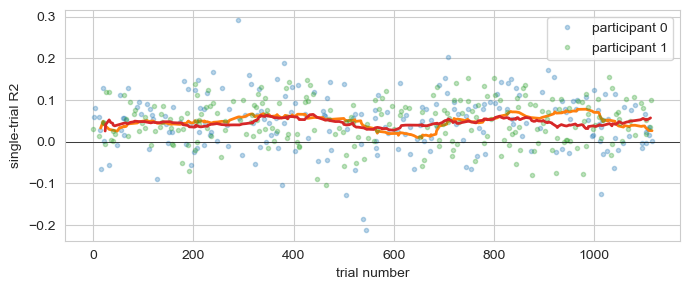

In [18]:
# ----------------------------------------------------------------------
# Single-trial R2 of the test trials vs trial number (drift check)
# ----------------------------------------------------------------------
def explained_variance_per_channel(Y, P):
    """1 - Var(Y - P) / Var(Y), per electrode: like R2 but ignores a constant offset."""
    with np.errstate(invalid="ignore", divide="ignore"):
        return 1 - (Y - P).var(axis=0) / Y.var(axis=0)

# in the per-trial loop, replace shape_r2_per_channel by:
#     "r2": np.nanmean(explained_variance_per_channel(Y_te[m], P[m]))

W = tuner2.maps_from(~test_mask)
X = tuner2.design(best2, W, ~test_mask, "drift")
te = tuner2.pts(test_mask)
P = tuner2._predict(X, te, W)
Y_te, ri_te, ei_te = tuner2.Y[te], tuner2.ri[te], tuner2.ei[te]

rows = []
for r, e in sorted(set(zip(ri_te, ei_te))):
    m = (ri_te == r) & (ei_te == e)
    rows.append({"recording": epoch_data.recording.values[r],
                 "epoch": int(epoch_data.epoch.values[e]),
                 "r2": np.nanmean(explained_variance_per_channel(Y_te[m], P[m]))})
per_trial = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 3))
for rec, dd in per_trial.groupby("recording"):
    dd = dd.sort_values("epoch")
    ax.plot(dd["epoch"], dd["r2"], ".", alpha=0.3, label=f"participant {rec}")
    ax.plot(dd["epoch"], dd["r2"].rolling(30, min_periods=5).mean(), lw=2)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("trial number")
ax.set_ylabel("single-trial R2")
ax.legend()
plt.tight_layout()

**Result:** no visible trend across the session.

### 4.2 Correlation vs R²
corr² is the highest R² reachable by rescaling and shifting the prediction.
Comparing it with R² tells us whether the amplitude of the prediction is the limiting factor.

In [19]:
corr_te = np.nanmean(pearson(Y_te, P))                       # same predictions as above
r2_te = np.nanmean(shape_r2_per_channel(Y_te, P))
print(f"test: R2 = {r2_te:.4f}, corr = {corr_te:.4f}")

test: R2 = 0.0204, corr = 0.1505


**Result:** corr = 0.15, so corr² ≈ 0.023, close to R² = 0.020. The amplitude and offset are already nearly optimal; the limit is what the prediction covers (4 short events), not how it is scaled.

corrélation² = le R² maximal qu'on obtiendrait en ajustant parfaitement l'amplitude et le décalage de la prédiction.

corrélation = 0,15 → corrélation² ≈ 0,023
R² obtenu = 0,020

Les deux sont presque égaux. Donc l'amplitude et le décalage de la prédiction sont déjà quasiment optimaux. Les remettre à l'échelle ne gagnerait presque rien (0,020 → 0,023 au mieux).

Ce que ça veut dire : le problème n'est pas l'amplitude. La prédiction est bien dosée, mais elle ne ressemble que faiblement au signal (corrélation 0,15). Ce qui limite, c'est ce qu'elle couvre : 4 bosses courtes, alors que l'EEG contient beaucoup d'autres choses (activité lente, bruit, autres processus).

## 5. Comparison of all models on the same test trials

| Metric | What it measures |
|---|---|
| R² (pooled) | Fit over all test samples, including the per-trial offset and slow activity |
| corr (pooled) | Shape similarity, ignoring amplitude |
| EV per trial | Variance explained within each trial, ignoring its offset. This is the trial-to-trial variability HMP claims to capture |

In [20]:
# ----------------------------------------------------------------------
# Same test trials, same metrics, for every model
# ----------------------------------------------------------------------
def explained_variance_per_channel(Y, P):
    with np.errstate(invalid="ignore", divide="ignore"):
        return 1 - (Y - P).var(axis=0) / Y.var(axis=0)

def all_scores(Y, P, ri, ei):
    """Pooled R2, pooled corr, and mean single-trial explained variance."""
    per_trial = []
    for r, e in set(zip(ri, ei)):
        m = (ri == r) & (ei == e)
        per_trial.append(np.nanmean(explained_variance_per_channel(Y[m], P[m])))
    return {"R2 (pooled)": np.nanmean(shape_r2_per_channel(Y, P)),
            "corr (pooled)": np.nanmean(pearson(Y, P)),
            "EV per trial (mean)": np.nanmean(per_trial)}

te = tuner2.pts(test_mask)
Y_te, ri_te, ei_te, si_te = tuner2.Y[te], tuner2.ri[te], tuner2.ei[te], tuner2.si[te]

# 1. HMP, learned shapes
W = tuner2.maps_from(~test_mask)
P_tuned = tuner2._predict(tuner2.design(best2, W, ~test_mask, "tab"), te, W)

# 2. HMP, 50 ms half-sines
P_50 = tuner2._predict(tuner2.design({e: 50 for e in range(4)}, W, ~test_mask, "tab"), te, W)

# 3. HMP, shuffled times (same points: the RTs are unchanged)
W_s = tuner_shuf.maps_from(~test_mask)
P_shuf = tuner_shuf._predict(tuner_shuf.design(best2, W_s, ~test_mask, "tab"), tuner_shuf.pts(test_mask), W_s)

# 4. ERP of the training trials (the `erp` array from the ERP-baseline cell)
P_erp = erp[ri_te, si_te]

table = pd.DataFrame({name: all_scores(Y_te, P, ri_te, ei_te)
                      for name, P in [("ERP", P_erp),
                                      ("HMP learned shapes", P_tuned),
                                      ("HMP 50 ms", P_50),
                                      ("HMP shuffled times", P_shuf)]}).T
print(table.round(4))

                    R2 (pooled)  corr (pooled)  EV per trial (mean)
ERP                      0.0323         0.1795               0.0380
HMP learned shapes       0.0204         0.1505               0.0471
HMP 50 ms                0.0129         0.1262               0.0378
HMP shuffled times      -0.0804         0.0596              -0.2232


**Result:** the ERP wins on pooled R² (0.032 vs 0.020), but HMP with learned shapes wins on explained variance per trial (0.047 vs 0.038, ≈ +25 %). HMP places each event at its own latency in each trial, whereas the ERP places the same curve at the same latency in every trial. With shuffled times, the per-trial EV collapses (−0.22).

Ce tableau change la conclusion : HMP fait mieux que l'ERP sur ce qui compte pour lui.

Ce que montre chaque colonne

R² global : l'ERP gagne (0,032 contre 0,020). Mais ce score mélange tout : le niveau moyen de chaque essai, l'activité lente commune à tous les essais, et les variations à l'intérieur des essais.

Variance expliquée par essai : c'est HMP avec les formes apprises qui gagne (0,047 contre 0,038 pour l'ERP).

HMP, formes apprises : 0,047 → le meilleur ;
ERP : 0,038, à égalité avec HMP 50 ms : 0,038 ;
HMP, moments mélangés : −0,22 → très mauvais.
L'interprétation
À l'intérieur de chaque essai, HMP avec les bonnes formes explique plus que l'ERP (~+25 %). C'est logique : l'ERP met la même courbe à la même place dans tous les essais, alors que HMP place les events au moment où ils ont lieu dans cet essai. C'est exactement l'argument du papier HMP : la moyenne efface la variabilité d'un essai à l'autre, HMP la capte.
Le timing est la clé : avec des moments mélangés, la variance expliquée s'effondre (−0,22).
Pourquoi l'ERP gagne quand même en R² global : ce score est sensible au niveau et à l'activité lente communs à tous les essais, que l'ERP reproduit et que 4 bosses courtes ne couvrent pas.

### 5.1 Paired test, HMP vs ERP, trial by trial

In [21]:
def ev_per_trial(Y, P, ri, ei):
    out = {}
    for r, e in set(zip(ri, ei)):
        m = (ri == r) & (ei == e)
        out[(r, e)] = np.nanmean(explained_variance_per_channel(Y[m], P[m]))
    return pd.Series(out)

ev_hmp = ev_per_trial(Y_te, P_tuned, ri_te, ei_te)
ev_erp = ev_per_trial(Y_te, P_erp, ri_te, ei_te)
diff = (ev_hmp - ev_erp).dropna()

print(f"mean difference = {diff.mean():.4f}, SE = {diff.std(ddof=1) / np.sqrt(len(diff)):.4f}")
print(f"HMP better in {(diff > 0).mean():.0%} of the {len(diff)} test trials")

mean difference = 0.0091, SE = 0.0033
HMP better in 56% of the 462 test trials


**Result:** mean difference 0.0091 (SE 0.0033, ≈ 2.8 SE), and HMP is better in 56 % of the 462 test trials. The advantage is consistent but small.

Différence moyenne = 0,0091, erreur standard = 0,0033 : la différence vaut ~2,8 fois son erreur standard, au-dessus du seuil de ~2. Elle est peu probable par hasard.
HMP gagne dans 56 % des 462 essais : un peu plus d'un essai sur deux. Sur 462 essais, 56 % est aussi nettement au-dessus de 50 % (environ 2,6 erreurs standard).

Les deux indicateurs vont dans le même sens. Mais l'avantage n'est pas massif : HMP ne gagne pas dans tous les essais, il gagne un peu plus souvent, et un peu plus en moyenne.

## 6. Scalp maps fitted by least squares
Instead of averaged maps, the maps (plus an intercept) are fitted by least squares on the training trials, per participant. This tests whether HMP's maps are suboptimal for prediction.

In [26]:
tuner3 = EventShapeCV(epoch_data, times, weights, epoch_data.sfreq, maps="lstsq")
cv3, best3 = tuner3.cross_validate(grid, folds, half_width="all", n_passes=3)
res_ls = tuner3.evaluate(best3, test_mask, half_width=HW)
print(best3, f"overall R2 = {res_ls['r2_overall']:.4f}")

# add it to the comparison table (same test points as the other models)
table.loc["HMP learned + least squares"] = all_scores(Y_te, res_ls["prediction"], ri_te, ei_te)
print(table.round(4))

5 folds, window = +-all samples, 28 shapes, 4 events, maps = lstsq
pass 1, event 0: best shape 600 (mean R2 = 0.0283)
pass 1, event 1: best shape learned:10 (mean R2 = 0.0286)
pass 1, event 2: best shape learned:25 (mean R2 = 0.0300)
pass 1, event 3: best shape learned:25 (mean R2 = 0.0301)
pass 2, event 0: best shape 600 (mean R2 = 0.0301)
pass 2, event 1: best shape learned:10 (mean R2 = 0.0301)
pass 2, event 2: best shape learned:25 (mean R2 = 0.0301)
pass 2, event 3: best shape learned:25 (mean R2 = 0.0301)
{0: 600, 1: 'learned:10', 2: 'learned:25', 3: 'learned:25'} overall R2 = 0.0316
                             R2 (pooled)  corr (pooled)  EV per trial (mean)
ERP                               0.0323         0.1795               0.0380
HMP learned shapes                0.0204         0.1505               0.0471
HMP 50 ms                         0.0129         0.1262               0.0378
HMP shuffled times               -0.0804         0.0596              -0.2232
HMP learned + leas

**Result:** pooled R² increases (0.020 → 0.032), but the per-trial EV decreases slightly (0.047 → 0.044).

**Why:** the CV picks a 600 ms half-sine for event 0, which acts as a slow background covering most of the trial, and the intercept corrects each electrode's mean level. The gain comes from slow, common activity (what the ERP captures), not from better events. The ramp of event 3 is no longer selected.

Ce résultat est instructif : les least squares font monter le R² global, mais pas ce qui compte pour HMP.

R² global : nette hausse (0,020 → 0,032), au niveau de l'ERP.
Variance expliquée par essai : légère baisse (0,047 → 0,044).

Donc les least squares expliquent mieux le signal global, mais un peu moins bien les variations à l'intérieur de chaque essai, qui est justement ce que HMP prétend capter.

Pourquoi : regarde les formes choisies

{0: 600, 1: 'learned:10', 2: 'learned:25', 3: 'learned:25'}

Event 0 → demi-sinus de 600 ms. Ce n'est plus un event : une bosse de 600 ms autour du premier event couvre une grande partie de l'essai. Avec des cartes libres (least squares), elle sert de « fond lent » qui capte l'activité lente commune à tous les essais, exactement ce que fait l'ERP.
Event 3 → learned:25 au lieu de learned:100 : la rampe n'est plus choisie, parce que la bosse de 600 ms de l'event 0 absorbe déjà l'activité lente.
L'intercept corrige en plus le niveau moyen par électrode.

Le gain en R² global vient donc de l'activité lente et du niveau moyen, pas de meilleurs events. Et ça déforme l'interprétation : l'event 0 devient un fond de 600 ms, et la rampe de l'event 3 disparaît.

### 6.1 Least squares with widths below 300 ms
Same, but without the very wide half-sines, so that no event can turn into a slow background.

In [27]:
grid_short = [20, 30, 40, 50, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280,
              "learned:10", "learned:25", "learned:50", "learned:100"]

cv3b, best3b = tuner3.cross_validate(grid_short, folds, half_width="all", n_passes=3)
res_ls_b = tuner3.evaluate(best3b, test_mask, half_width=HW)
print(best3b, f"overall R2 = {res_ls_b['r2_overall']:.4f}")

table.loc["HMP learned + least squares (widths < 300 ms)"] = all_scores(
    Y_te, res_ls_b["prediction"], ri_te, ei_te)
print(table.round(4))

5 folds, window = +-all samples, 20 shapes, 4 events, maps = lstsq
pass 1, event 0: best shape 280 (mean R2 = 0.0268)
pass 1, event 1: best shape learned:10 (mean R2 = 0.0271)
pass 1, event 2: best shape learned:100 (mean R2 = 0.0290)
pass 1, event 3: best shape 280 (mean R2 = 0.0294)
pass 2, event 0: best shape 280 (mean R2 = 0.0294)
pass 2, event 1: best shape learned:10 (mean R2 = 0.0294)
pass 2, event 2: best shape learned:100 (mean R2 = 0.0294)
pass 2, event 3: best shape 280 (mean R2 = 0.0294)
{0: 280, 1: 'learned:10', 2: 'learned:100', 3: 280} overall R2 = 0.0294
                                               R2 (pooled)  corr (pooled)  \
ERP                                                 0.0323         0.1795   
HMP learned shapes                                  0.0204         0.1505   
HMP 50 ms                                           0.0129         0.1262   
HMP shuffled times                                 -0.0804         0.0596   
HMP learned + least squares           

**Conclusion:** the main analysis keeps the averaged maps, which give the best within-trial EV and interpretable shapes (a ramp for event 3, short peaks for the others). Least-squares maps don't improve the within-trial fit, so HMP's averaged maps are already close to optimal for what the model aims to explain.

Ce que je retiendrais
L'analyse principale reste avec les cartes moyennes : meilleure variance expliquée par essai, et des formes interprétables (rampe de l'event 3, pics courts pour les autres).
Les least squares en annexe, avec cette conclusion : « Des cartes ajustées par least squares n'améliorent pas la variance expliquée à l'intérieur des essais (0,044 contre 0,047). Le gain en R² global vient d'une bosse très large sur l'event 0 et d'un intercept, qui capturent l'activité lente commune aux essais, comme l'ERP. Les cartes moyennes de HMP sont donc déjà quasi optimales pour ce que le modèle cherche à expliquer. »
Ça donne aussi une réponse claire à Gabriel sur l'intérêt des least squares : ils servaient à vérifier les cartes de HMP, et la vérification est positive.